# 03 · Findings: messages, orders, the opening cross

Spark SQL over the decoded tables, plus a few cross-checks in pandas. Same data as before: Nasdaq ITCH 5.0, 30 December 2019, 04:00 to 09:30:36.

Tables are produced once by `python -m itch_forensics.build` (8.7M messages become 10 Parquet tables); each audit is a SQL file in `sql/`.

In [1]:
import pathlib, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itch_forensics.spark import get_spark, register, run_sql
from itch_forensics.decode import decode_all
from itch_forensics.framing import index_messages
from itch_forensics.checks import match_number_duplicates, directory_mismatches

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PARQUET = pathlib.Path("../data/parquet")
if not (PARQUET / "messages.parquet").exists():
    subprocess.run([sys.executable, "-m", "itch_forensics.build", "--raw", "../data/itch.bin", "--out", str(PARQUET)], check=True)
spark = get_spark("itch-findings"); register(spark, PARQUET)
print({t: spark.table(t).count() for t in ["messages", "add_order", "execution", "delete", "replace", "cancel", "cross", "noii"]})

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45241 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45241 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/10 20:40:22 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/10 20:40:22 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/10/10 20:40:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


{'messages': 8733895, 'add_order': 3932096, 'execution': 49491, 'delete': 2362895, 'replace': 532923, 'cancel': 519657, 'cross': 8906, 'noii': 1073085}


## 1 · Message rate: the open is a burst, not a ramp

`sql/01_message_rate.sql`: messages per wall-clock second, labelled by session phase.

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


                          total  median_per_s  peak_per_s
phase                                                    
before 04:00             241732        3738.0       81901
pre-market 04:00-09:30  6454987         172.0       45346
regular hours           2037176       35003.0      527644


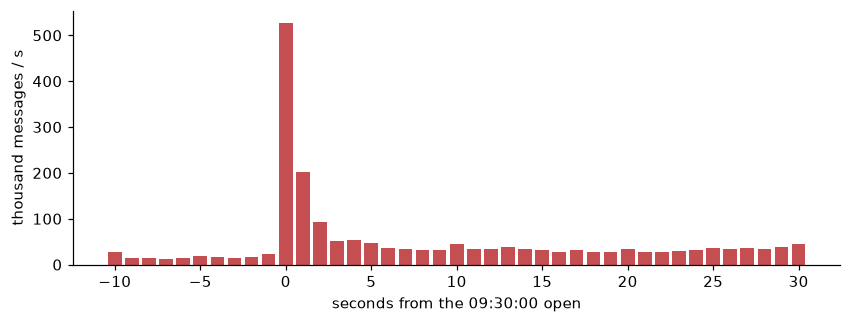

peak second: 527,644 messages, 3,068x the median pre-market second (172)


In [2]:
rate = run_sql(spark, "01_message_rate")
print(rate.groupby("phase").messages.agg(total="sum", median_per_s="median", peak_per_s="max").to_string())
open_win = rate[(rate.second_of_day >= 34200 - 10) & (rate.second_of_day <= 34200 + 30)]
fig, ax = plt.subplots(figsize=(9, 3)); ax.bar(open_win.second_of_day - 34200, open_win.messages / 1e3, color="#C44E52")
ax.set_xlabel("seconds from the 09:30:00 open"); ax.set_ylabel("thousand messages / s"); plt.show()
pk = rate.nlargest(1, "messages").iloc[0]
med_pre = rate[rate.phase == "pre-market 04:00-09:30"].messages.median()
print(f"peak second: {int(pk.messages):,} messages, {pk.messages / med_pre:,.0f}x the median pre-market second ({med_pre:.0f})")

## 2 · Order-to-trade ratio: most displayed orders never trade

`sql/02_order_to_trade.sql`: for symbols with at least 1,000 added orders and at least one execution, order-entry messages (add, delete, replace, cancel) per execution message. Pre-market is thin, so this is a statement about this window, not the whole day.

In [3]:
ott = run_sql(spark, "02_order_to_trade", min_adds=1000)
print(f"{len(ott)} symbols qualify")
print(ott.messages_per_execution.describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
ott.head(8)

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


401 symbols qualify
count      401.0
mean      1386.7
std       4035.4
min          3.8
25%         71.0
50%        200.3
75%        817.5
90%       3070.0
max      41401.0


,stock,adds,deletes,replaces,cancels,executions,shares_executed,messages_per_execution
0,PUK,31609,31468,749,18976,2,200,41401.0
1,SSL,17121,17011,60,3739,1,10,37931.0
2,ZEAL,11434,11338,0,3145,1,6,25917.0
3,UN,68338,68154,9528,39503,8,900,23190.4
4,SAP,32733,32607,321,33198,5,1200,19771.8
5,SSO,8575,8422,907,2,1,387,17906.0
6,RELX,18533,18420,106,7125,3,720,14728.0
7,NGG,22008,21882,2683,9008,4,767,13895.3


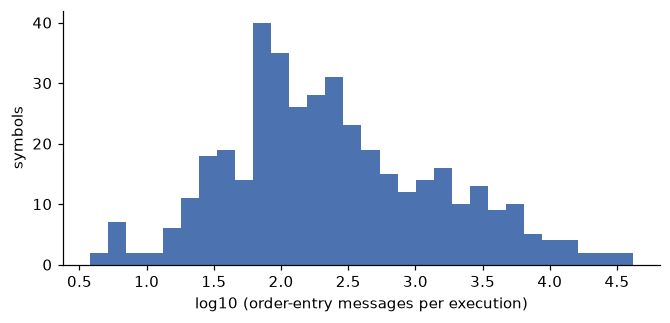

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(ott.messages_per_execution), bins=30, color="#4C72B0")
ax.set_xlabel("log10 (order-entry messages per execution)"); ax.set_ylabel("symbols"); plt.show()

## 3 · How long do displayed orders live?

`sql/03_order_lifetime.sql`. An order ends at the first of a delete, a replace, or the point where executions and cancels have used up all its shares; each order id is its own order.

**A trap in the obvious version.** The sample stops at 09:30:36, so an order added a few seconds before the stop has had no chance to end. If you only count orders that ended inside the window, short lives are over-represented. The fix is a *cohort*: only orders added early enough that every one of them was observable for at least 10 minutes. For those, any life shorter than 10 minutes is fully observed. All figures below are for this window, which is almost entirely pre-market quoting.

In [5]:
end_ns = int(spark.sql("select max(ts_ns) as m from messages").first().m)
FOLLOW_S = 600
cohort_end = end_ns - FOLLOW_S * 10**9
life = run_sql(spark, "03_order_lifetime", cohort_end_ns=cohort_end)
n = int(life.orders.sum())
clock = lambda ns: str(pd.to_timedelta(ns, unit="ns")).split(" ")[-1][:8]
print(f"cohort: {n:,} orders added up to {clock(cohort_end)}, each observed for at least {FOLLOW_S // 60} minutes (sample ends {clock(end_ns)})")
pct = (100 * life.pivot_table(index="lifetime", columns="how_it_ended", values="orders", aggfunc="sum", fill_value=0) / n).round(2)
pct.assign(total=pct.sum(axis=1).round(2))

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


cohort: 2,307,548 orders added up to 09:20:36, each observed for at least 10 minutes (sample ends 09:30:36)


how_it_ended,deleted,executed or cancelled in full,replaced,still resting after follow-up,total
lifetime,,,,,
1 under 1 ms,4.16,0.03,0.62,0.00,4.81
2 1-10 ms,8.08,0.02,0.87,0.00,8.97
3 10-100 ms,9.68,0.02,0.73,0.00,10.43
4 100 ms-1 s,16.28,0.05,2.38,0.00,18.71
5 1-10 s,20.69,0.12,2.64,0.00,23.45
6 10-60 s,13.23,0.12,1.88,0.00,15.23
7 1 min to follow-up,8.15,0.27,2.74,0.00,11.16
8 survived the follow-up,0.00,0.00,0.00,7.26,7.26


In [6]:
fast = life[life.lifetime.str[0].isin(list("123"))].orders.sum()
fast1s = life[life.lifetime.str[0].isin(list("1234"))].orders.sum()
alive = life[life.lifetime.str[0] == "8"].orders.sum()
print(f"ended within 100 ms : {100 * fast / n:5.1f}% of the cohort")
print(f"ended within 1 s    : {100 * fast1s / n:5.1f}%")
print(f"still resting after 10 minutes: {100 * alive / n:5.1f}%")
print("how they ended:", (100 * life.groupby('how_it_ended').orders.sum() / n).round(1).to_dict())

ended within 100 ms :  24.2% of the cohort
ended within 1 s    :  42.9%
still resting after 10 minutes:   7.3%
how they ended: {'deleted': 80.3, 'executed or cancelled in full': 0.6, 'replaced': 11.8, 'still resting after follow-up': 7.3}


To see how much the cohort matters, the same question without it (every order, however late it was added), asked of only the orders that ended inside the window:

In [7]:
everyone = run_sql(spark, "03_order_lifetime", cohort_end_ns=end_ns)
ended = everyone[~everyone.lifetime.str.startswith("8")]
naive = ended[ended.lifetime.str[0].isin(list("123"))].orders.sum() / ended.orders.sum()
cohort_ended = life[~life.lifetime.str.startswith("8")]
among_ended = cohort_ended[cohort_ended.lifetime.str[0].isin(list("123"))].orders.sum() / cohort_ended.orders.sum()
print(f"under 100 ms, among orders that ended in the window, no cohort   : {100 * naive:5.1f}%")
print(f"under 100 ms, among cohort orders that ended                      : {100 * among_ended:5.1f}%")
print(f"under 100 ms, among ALL cohort orders (the unbiased question)     : {100 * fast / n:5.1f}%")

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


under 100 ms, among orders that ended in the window, no cohort   :  26.2%
under 100 ms, among cohort orders that ended                      :  26.1%
under 100 ms, among ALL cohort orders (the unbiased question)     :  24.2%


Conditioning on "ended" makes lives look shorter than they are, because the long-lived orders are still resting when the sample stops. The last line is the one that answers "how long does a displayed order live": about a quarter end within 100 ms, but most live much longer, and 7% outlast ten minutes.



## 4 · Trading halts: do stocks execute while halted?

`sql/05_halts.sql`. A trading-action (`H`) message sets a stock's state (`T` trading, `H` halted, `P` paused, `Q` quotation only) until its next message. Executions and trades should only happen in state `T`.

In [8]:
run_sql(spark, "05_halts")

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,state,what,events,stocks
0,T,cross trade (Q),3086,3086
1,T,non-displayed trade (P),13036,1904
2,T,order executed (E/C),49491,2807


In [9]:
ta = spark.table("trading_action").toPandas()
halted = ta[ta.trading_state == "H"]
adds = spark.table("add_order").groupBy("locate").agg({"seq": "count"}).toPandas().rename(columns={"count(seq)": "adds"}).set_index("locate").adds
ex = spark.table("execution").groupBy("locate").count().toPandas().set_index("locate")["count"]
first = halted.groupby("locate").ts_ns.min()
rows = []
for loc, t0 in first.items():
    n_after = spark.sql(f"select count(*) c from add_order where locate = {loc} and ts_ns >= {int(t0)}").first().c
    rows.append({"stock": ta[ta.locate == loc].stock.iloc[0], "halted from": clock(t0), "orders added after": n_after,
                 "executions in the whole sample": int(ex.get(loc, 0))})
pd.DataFrame(rows)

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,stock,halted from,orders added after,executions in the whole sample
0,BRQS,03:09:14,14,0
1,DNJR,03:09:14,26,0
2,DPW,07:01:38,0,0
3,IPDN,03:09:14,22,0
4,JOYY,03:36:00,0,0
5,MKD,04:00:00,42,0
6,PNRL,03:09:15,175,0
7,SPSK,03:36:00,0,0
8,SVA,03:09:15,15,0
9,ZJZZT,07:01:15,5,0


No execution or trade happened while a stock was halted. **This is weak evidence on this window.** Only 11 stocks are halted, several from before the day's first quote, and none of them executed anything at any time in the sample, so the check passes by default. Orders are still accepted during a halt (the "orders added after" column), which is expected.

A check is only worth anything if it can fail. Mark a busy stock as halted from midnight and the same query must report its executions:

In [10]:
busy = int(ex.idxmax())
fake = ta.copy(); fake.loc[fake.locate == busy, "trading_state"] = "H"; fake.loc[fake.locate == busy, "ts_ns"] = 0
spark.createDataFrame(fake).createOrReplaceTempView("trading_action")
control = run_sql(spark, "05_halts"); register(spark, PARQUET)          # restore the real table afterwards
print(f"control: {ta[ta.locate == busy].stock.iloc[0]} marked halted from 00:00 ->")
control[control.state == "H"]

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


control: SVRA marked halted from 00:00 ->


,state,what,events,stocks
0,H,cross trade (Q),1,1
1,H,non-displayed trade (P),2037,1
2,H,order executed (E/C),6129,1


## 5 · The opening cross

At 09:30:00 each symbol with enough interest opens through an auction. Nasdaq publishes the *indicative* cross price in `I` (imbalance) messages, once a second from 09:28, and then the realised cross as a `Q` message. How well does the last indicative price predict the realised one?

In [11]:
buf = pathlib.Path("../data/itch.bin").read_bytes(); idx = index_messages(buf); fr = decode_all(buf, idx)
Q, I = fr["Q"], fr["I"].sort_values("seq")
last = I.groupby("locate").tail(1).set_index("locate")
x = Q.set_index("locate").join(last[["near_price", "paired", "ts_ns"]], rsuffix="_noii")
x["traded"] = x.shares > 0
x["lag_s"] = (x.ts_ns - x.ts_ns_noii) / 1e9
print(f"opening cross messages: {len(Q):,} (one per symbol);  with executed shares: {int(x.traded.sum()):,};  "
      f"no cross: {int((~x.traded).sum()):,}")
print(f"indicative message cadence: median gap {I.groupby('locate').ts_ns.diff().median() / 1e9:.2f} s, "
      f"first at {pd.to_timedelta(I.ts_ns.min(), unit='ns')}".replace("0 days ", ""))
t = x[x.traded]
same = (t.price == t.near_price)
rel = ((t.price - t.near_price).abs() / t.near_price.replace(0, np.nan))[~same]
print(f"\nof {len(t):,} symbols that traded in the cross:")
print(f"  realised price == last indicative near price : {100 * same.mean():.1f}%")
print(f"  realised shares == last indicative paired    : {100 * (t.shares == t.paired).mean():.1f}%")
print(f"  when different, price moved by median {100 * rel.median():.2f}% (max {100 * rel.max():.1f}%)")
print(f"  last indicative message came {t.lag_s.median():.2f} s before the cross (max {t.lag_s.max():.2f} s)")

opening cross messages: 8,906 (one per symbol);  with executed shares: 3,086;  no cross: 5,820
indicative message cadence: median gap 1.00 s, first at 09:28:00.000515110

of 3,086 symbols that traded in the cross:
  realised price == last indicative near price : 75.5%
  realised shares == last indicative paired    : 62.0%
  when different, price moved by median 0.08% (max 3.1%)
  last indicative message came 0.91 s before the cross (max 1.61 s)


The indicative price is a snapshot up to about 1.6 seconds old, so a difference is not an error; it is the book moving in the last second. Roughly three quarters of crosses match the snapshot exactly, and the rest differ by a small fraction of a percent at the median.

## 6 · Shared match numbers

A match number is supposed to identify one execution. Counting how many appear on more than one message:

In [12]:
dups = match_number_duplicates(fr); print(dups)
m = pd.concat([fr[t][["seq", "locate", "ts_ns", "ref", "match", "shares"]].assign(type=t) for t in "EC"])
m[m.match.duplicated(keep=False)].sort_values(["match", "seq"])

{'matched_messages': 71433, 'distinct_match_numbers': 71430, 'messages_sharing_a_match_number': 6, 'by_type_of_duplicates': {'E': 3, 'C': 3}}


,seq,locate,ts_ns,ref,match,shares,type
0,5265119,7603,34086523596953,9489356,50460,100,C
26811,5265120,7603,34086523596953,9489320,50460,100,E
1214,7892573,7781,34212145975256,10746928,289296,100,C
39504,7892574,7781,34212145975256,10746920,289296,100,E
1252,8053636,4184,34216906953832,6809234,291861,100,C
41523,8053637,4184,34216906953832,6809214,291861,100,E


Three match numbers appear twice. Each pair is one `E` and one `C` message with the same nanosecond timestamp, the same stock, 100 shares each, and **different order references**. That fits a single trade in which both counterparties were displayed orders, reported once per side. It is an interpretation of the pattern, not something the sample can prove. For anyone summing executed shares, the practical point is that the match number is not a unique key for execution messages: use `(match, ref)`.

## 7 · Reference-data consistency

In [13]:
directory_mismatches(fr)

,type,messages,symbol_mismatch,locate_not_in_directory
0,A,3179119,0,0
1,F,752977,0,0
2,P,13036,0,0


In [14]:
R = fr["R"]
print(f"directory entries: {len(R):,}; distinct symbols: {R.stock.nunique():,}; locates 1..{R.locate.max()} contiguous: "
      f"{(sorted(R.locate) == list(range(1, len(R) + 1)))}")

directory entries: 8,906; distinct symbols: 8,906; locates 1..8906 contiguous: True


The symbol carried in every add and trade message agrees with the stock directory entry for its locate code, so joining on `locate` alone is safe.

## Summary

In [15]:
msgs = rate.messages.sum()
print(f"{msgs:,} messages decoded; every length matches the ITCH 5.0 spec; timestamps never decrease")
print("order book replay (notebook 02): no inconsistencies; resting shares reconcile by order and by price level")
print(f"busiest second is {pk.messages / med_pre:,.0f}x a median pre-market second")
print(f"orders added before {clock(cohort_end)} (n={n:,}), each observed 10 minutes: {100 * fast / n:.1f}% ended within 100 ms, "
      f"{100 * fast1s / n:.1f}% within 1 s, {100 * alive / n:.1f}% still resting")
print(f"opening cross price equals the last indicative price for {100 * same.mean():.0f}% of symbols that traded")
print(f"{dups['messages_sharing_a_match_number']} execution messages share {dups['messages_sharing_a_match_number'] // 2} match numbers")
spark.stop()

8,733,895 messages decoded; every length matches the ITCH 5.0 spec; timestamps never decrease
order book replay (notebook 02): no inconsistencies; resting shares reconcile by order and by price level
busiest second is 3,068x a median pre-market second
orders added before 09:20:36 (n=2,307,548), each observed 10 minutes: 24.2% ended within 100 ms, 42.9% within 1 s, 7.3% still resting
opening cross price equals the last indicative price for 76% of symbols that traded
6 execution messages share 3 match numbers
